# Figures 9, 10, 11, 12, 13, 14, and 15 of Pucha et al. (2026)

In [1]:
import numpy as np

from astropy.io import fits
from astropy.table import Table, join, Column, vstack

import sys
sys.path.append('/global/cfs/cdirs/desi/users/raga19/repos/EmFit/py/')
sys.path.append('/global/cfs/cdirs/desi/users/raga19/repos/DESI_Project/py/')

import emline_fitting as emfit
import spec_utils
import plot_utils

import bpt
import utils

import matplotlib.pyplot as plt

In [2]:
## Making the matplotlib plots look nicer
settings = {
    'mathtext.fontset': 'stix',
    'font.family': 'STIXGeneral',
    'font.size':22,
    'axes.labelsize': 'large',
    'lines.markersize': 5,
    'axes.linewidth':2.0,
    'xtick.major.size':6.0,
    'xtick.minor.size':4.0,
    'xtick.major.width':2.5,
    'xtick.minor.width':1.5,
    'xtick.direction':'in', 
    'xtick.minor.visible':True,
    'xtick.top':True,
    'ytick.major.size':6.0,
    'ytick.minor.size':4.0,
    'ytick.major.width':2.5,
    'ytick.minor.width':1.5,
    'ytick.direction':'in', 
    'ytick.minor.visible':True,
    'ytick.right':True,
    'contour.linewidth':3.0,
    'savefig.bbox': 'tight',
    'savefig.dpi': 200,
}

plt.rcParams.update(**settings)

In [3]:
def normal_fit(table, index, title = None):
    """
    Function to plot the spectra+fits from the table of parameters for default cases.

    Parameters
    ----------
    table : Astropy table
        Table of fit parameters

    index : int
        Index number of the source in the table

    title : str
        Title of the plot. Default is None.

    Returns
    -------
    fig : Figure
        Figure with spectra + best-fit model
    """

    ## Required variables
    specprod = table['SPECPROD'].astype(str).data[index]
    survey = table['SURVEY'].astype(str).data[index]
    program = table['PROGRAM'].astype(str).data[index]
    healpix = table['HEALPIX'].data[index]
    targetid = table['TARGETID'].data[index]
    z = table['Z'].data[index]

    ## Accessing the rest-frame spectra
    _, lam_rest, flam_rest, ivar_rest = spec_utils.get_emline_spectra(specprod, survey, program, healpix, \
                                                                     targetid, z, rest_frame = True)
    if (title == None):
        title = f'TARGETID: {targetid}; z : {round(z, 2)}'

    ## Select [OIII] region 
    oiii_lam = (lam_rest >= 4900)&(lam_rest <= 5050)
    lam_oiii = lam_rest[oiii_lam]
    flam_oiii = flam_rest[oiii_lam]

    ## Select [NII] + Ha region 
    nii_lam = (lam_rest >= 6470)&(lam_rest <= 6660)
    lam_nii = lam_rest[nii_lam]
    flam_nii = flam_rest[nii_lam]

    ## Select Hb region 
    hb_lam = (lam_rest >= 4800)&(lam_rest <= 4930)
    lam_hb = lam_rest[hb_lam]
    flam_hb = flam_rest[hb_lam]

    ## Select [SII] region 
    sii_lam = (lam_rest >= 6650)&(lam_rest <= 6800)
    lam_sii = lam_rest[sii_lam]
    flam_sii = flam_rest[sii_lam]

    ## Construct Fits
    fits_def = emfit.construct_fits_from_table.normal_fit(table, index)
    ## Separate the fits 
    hb_fit, oiii_fit, nii_ha_fit, sii_fit = fits_def
    ## Reduced chi2 values from the table
    rchi2_hb = table['HB_RCHI2'].data[index]
    rchi2_oiii = table['OIII_RCHI2'].data[index]
    rchi2_nii_ha = table['NII_HA_RCHI2'].data[index]
    rchi2_sii = table['SII_RCHI2'].data[index]

    fig = plt.figure(figsize = (40, 8))
    plt.suptitle(title, y = 0.93, fontsize = 28)
    gs = fig.add_gridspec(5, 16)

    ## Subplots for Hb
    hb = fig.add_subplot(gs[0:4, 0:4])
    hb_res = fig.add_subplot(gs[4:, 0:4], sharex = hb)

    ## Subplots for [OIII]
    oiii = fig.add_subplot(gs[0:4, 4:8])
    oiii_res = fig.add_subplot(gs[4:, 4:8], sharex = oiii)

    ## Subplots for [NII]+Ha
    ha = fig.add_subplot(gs[0:4, 8:12])
    ha_res = fig.add_subplot(gs[4:, 8:12], sharex = ha)

    ## Subplots for [SII]
    sii = fig.add_subplot(gs[0:4, 12:])
    sii_res = fig.add_subplot(gs[4:, 12:], sharex = sii)

    ############################################################################################
    ############################## Hb spectra + models #########################################

    hb.plot(lam_hb, flam_hb, color = 'k')
    hb.plot(lam_hb, hb_fit(lam_hb), color = 'r', lw = 4.0, ls = '--')
    hb.set(ylabel = '$F_{\lambda}$', xlabel = '')
    plt.setp(hb.get_xticklabels(), visible = False)

    ## Hb fits
    n_hb = hb_fit.n_submodels

    ## Hb continuum
    hb_cont = hb_fit['hb_cont'].amplitude.value

    ## Narrow component of Hb
    hb.plot(lam_hb, hb_fit['hb_n'](lam_hb) + hb_cont, color = 'orange', lw = 2.0)

    ## Outflow component of Hb, if available 
    if ('hb_out' in hb_fit.submodel_names):
        hb.plot(lam_hb, hb_fit['hb_out'](lam_hb) + hb_cont, color = 'orange', lw = 2.0)

    ## Broad component of Hb, if available
    if ('hb_b' in hb_fit.submodel_names):
        hb.plot(lam_hb, hb_fit['hb_b'](lam_hb) + hb_cont, color = 'blue', lw = 2.0)

    ## Rchi2 value
    hb.annotate('$H\\beta$', xy = (0.03, 0.9), \
                xycoords = (hb.get_yaxis_transform(), hb.get_xaxis_transform()), \
                fontsize = 28, color = 'k')
    hb.annotate('$\chi^{2}_{red}$ = '+str(round(rchi2_hb, 2)), xy = (0.03, 0.8), \
                xycoords = (hb.get_yaxis_transform(), hb.get_xaxis_transform()), \
                fontsize = 28, color = 'k')

    ## Hb fit residuals
    res_hb = (flam_hb - hb_fit(lam_hb))/flam_hb
    hb_res.scatter(lam_hb, res_hb, color = 'k', marker = '.', alpha = 0.7)
    hb_res.axhline(0.0, color = 'grey', ls = ':')
    hb_res.set(yticks = [0])
    hb_res.set(xlabel = '$\lambda_{rest}$', ylim = [-10, 10])

    ############################################################################################
    ############################## [OIII] spectra + models #####################################

    oiii.plot(lam_oiii, flam_oiii, color = 'k')
    oiii.plot(lam_oiii, oiii_fit(lam_oiii), color = 'r', lw = 4.0, ls = '--')
    oiii.set(ylabel = '$F_{\lambda}$', xlabel = '')
    plt.setp(oiii.get_xticklabels(), visible = False)

    n_oiii = oiii_fit.n_submodels
    names_oiii = oiii_fit.submodel_names

    ### [OIII] continuum
    oiii_cont = oiii_fit['oiii_cont'].amplitude.value

    ## [OIII]4959,5007 components, including outflow components, if available
    for ii in range(1, n_oiii):
        oiii.plot(lam_oiii, oiii_fit[names_oiii[ii]](lam_oiii) + oiii_cont, color = 'orange', lw = 2.0)

    ## Rchi2 value
    oiii.annotate('[OIII]4959,5007', xy = (0.03, 0.9), \
                  xycoords = (oiii.get_yaxis_transform(), oiii.get_xaxis_transform()),\
                  fontsize = 28, color = 'k')
    oiii.annotate('$\chi^{2}_{red}$ = '+str(round(rchi2_oiii, 2)), \
                  xy = (0.03, 0.8), \
                  xycoords = (oiii.get_yaxis_transform(), oiii.get_xaxis_transform()), \
                  fontsize = 28, color = 'k')

    ## [OIII] fit residuals
    res_oiii = (flam_oiii - oiii_fit(lam_oiii))/flam_oiii
    oiii_res.scatter(lam_oiii, res_oiii, color = 'k', marker = '.', alpha = 0.7)
    oiii_res.axhline(0.0, color = 'k', ls = ':')
    oiii_res.set(xlabel = '$\lambda_{rest}$', ylim = [-10, 10], yticks = [0])

    ############################################################################################
    ############################## [NII]+Ha spectra + models ###################################

    ha.plot(lam_nii, flam_nii, color = 'k')
    ha.plot(lam_nii, nii_ha_fit(lam_nii), color = 'r', lw = 4.0, ls = '--')
    ha.set(ylabel = '$F_{\lambda}$', xlabel = '')
    plt.setp(ha.get_xticklabels(), visible = False)    

    ## [NII] + Ha continuum
    nii_ha_cont = nii_ha_fit['nii_ha_cont'].amplitude.value

    ## Plot narrow components
    ha.plot(lam_nii, nii_ha_fit['nii6548'](lam_nii) + nii_ha_cont, color = 'orange', lw = 2.0)
    ha.plot(lam_nii, nii_ha_fit['nii6583'](lam_nii) + nii_ha_cont, color = 'orange', lw = 2.0)
    ha.plot(lam_nii, nii_ha_fit['ha_n'](lam_nii) + nii_ha_cont, color = 'orange', lw = 2.0)

    ## Outflow components, if available
    if ('nii6548_out' in nii_ha_fit.submodel_names):
        ha.plot(lam_nii, nii_ha_fit['nii6548_out'](lam_nii) + nii_ha_cont, color = 'orange', lw = 2.0)
        ha.plot(lam_nii, nii_ha_fit['nii6583_out'](lam_nii) + nii_ha_cont, color = 'orange', lw = 2.0)
        ha.plot(lam_nii, nii_ha_fit['ha_out'](lam_nii) + nii_ha_cont, color = 'orange', lw = 2.0)

    ## Broad component, if available
    if ('ha_b' in nii_ha_fit.submodel_names):
        ha.plot(lam_nii, nii_ha_fit['ha_b'](lam_nii) + nii_ha_cont, color = 'blue', lw = 2.0)

    ## Rchi2 value
    ha.annotate('$H\\alpha$ + [NII]6548,6583', xy = (0.03, 0.9),\
                xycoords = (ha.get_yaxis_transform(), ha.get_xaxis_transform()),\
                fontsize = 26, color = 'k')
    ha.annotate('$\chi^{2}_{red}$ = '+str(round(rchi2_nii_ha, 2)),\
                xy = (0.03, 0.8), xycoords = (ha.get_yaxis_transform(), ha.get_xaxis_transform()),\
                fontsize = 26, color = 'k')

    ## [NII]+Ha fit residuals
    res_nii = (flam_nii - nii_ha_fit(lam_nii))/flam_nii
    ha_res.scatter(lam_nii, res_nii, color = 'k', marker = '.', alpha = 0.7)
    ha_res.axhline(0.0, color = 'k', ls = ':')
    ha_res.set(xlabel = '$\lambda_{rest}$', ylim = [-10, 10], yticks = [0])

    ############################################################################################
    ############################## [SII] spectra + models ######################################

    sii.plot(lam_sii, flam_sii, color = 'k')
    sii.plot(lam_sii, sii_fit(lam_sii), color = 'r', lw = 4.0, ls = '--')
    sii.set(ylabel = '$F_{\lambda}$', xlabel = '')
    plt.setp(sii.get_xticklabels(), visible = False)

    ## [SII] fits
    n_sii = sii_fit.n_submodels
    names_sii = sii_fit.submodel_names

    ## [SII] continuum
    sii_cont = sii_fit['sii_cont'].amplitude.value

    ## All components of [SII], outflow components included, if available
    for ii in range(1, n_sii):
        sii.plot(lam_sii, sii_fit[names_sii[ii]](lam_sii) + sii_cont, color = 'orange')

    ## Rchi2 value
    sii.annotate('[SII]6716, 6731', xy = (0.03, 0.9),\
                 xycoords = (sii.get_yaxis_transform(), sii.get_xaxis_transform()),\
                 fontsize = 26, color = 'k')
    sii.annotate('$\chi^{2}_{red}$ = '+str(round(rchi2_sii, 2)), xy = (0.03, 0.8), \
                 xycoords = (sii.get_yaxis_transform(), sii.get_xaxis_transform()),\
                 fontsize = 26, color = 'k')

    ## [SII] fit residuals
    res_sii = (flam_sii - sii_fit(lam_sii))/flam_sii
    sii_res.scatter(lam_sii, res_sii, color = 'k', marker = '.', alpha = 0.7)
    sii_res.axhline(0.0, color = 'k', ls = ':')
    sii_res.set(xlabel = '$\lambda_{rest}$', ylim = [-10, 10], yticks = [0])
    plt.tight_layout()
    plt.subplots_adjust(hspace=0, wspace = 0.9)
    plt.close()

    return (fig)

In [4]:
def extreme_fit(table, index, title = None):
    """
    Function to plot the spectra+fits from the table of parameters for extreme BL cases.

    Parameters
    ----------
    table : Astropy table
        Table of fit parameters

    index : int
        Index number of the source in the table

    title : str
        Title of the plot. Default is None.

    Returns
    -------
    fig : Figure
        Figure with spectra + best-fit model
    """

    ## Required variables
    specprod = table['SPECPROD'].astype(str).data[index]
    survey = table['SURVEY'].astype(str).data[index]
    program = table['PROGRAM'].astype(str).data[index]
    healpix = table['HEALPIX'].data[index]
    targetid = table['TARGETID'].data[index]
    z = table['Z'].data[index]

    ## Accessing the rest-frame spectra
    _, lam_rest, flam_rest, ivar_rest = spec_utils.get_emline_spectra(specprod, survey, program, healpix, \
                                                                     targetid, z, rest_frame = True)
    if (title == None):
        title = f'TARGETID: {targetid}; z : {round(z, 2)}'

    ## Select Hb+[OIII] region
    hb_oiii_lam = (lam_rest >= 4700)&(lam_rest <= 5100)
    lam_hb_oiii = lam_rest[hb_oiii_lam]
    flam_hb_oiii = flam_rest[hb_oiii_lam]

    ## Select [NII]+Ha+[SII] region
    nii_ha_sii_lam = (lam_rest >= 6300)&(lam_rest <= 6800)
    lam_nii_ha_sii = lam_rest[nii_ha_sii_lam]
    flam_nii_ha_sii = flam_rest[nii_ha_sii_lam]

    ## Construct Fits
    fits_ebl = emfit.construct_fits_from_table.extreme_fit(table, index)
    ## Separate the fits 
    hb_oiii_fit, nii_ha_sii_fit = fits_ebl
    ## Rchi2 values
    hb_oiii_rchi2 = table['HB_OIII_RCHI2'].data[index]
    nii_ha_sii_rchi2 = table['NII_HA_SII_RCHI2'].data[index]

    fig = plt.figure(figsize = (40, 10))
    plt.suptitle(title, y = 0.93, fontsize = 28)
    gs = fig.add_gridspec(5, 16)

    ## Subplots for Hb+[OIII]
    hb = fig.add_subplot(gs[0:4, 0:8])
    hb_res = fig.add_subplot(gs[4:, 0:8], sharex = hb)

    ## Subplots for [NII]+Ha+[SII]
    ha = fig.add_subplot(gs[0:4, 8:])
    ha_res = fig.add_subplot(gs[4:, 8:], sharex = ha)

    ############################################################################################
    ############################ Hb + [OIII] spectra and models ################################

    hb.plot(lam_hb_oiii, flam_hb_oiii, color = 'k')
    hb.plot(lam_hb_oiii, hb_oiii_fit(lam_hb_oiii), color = 'r', lw = 4.0, ls = '--')
    hb.set(ylabel = '$F_{\lambda}$', xlabel = '')
    plt.setp(hb.get_xticklabels(), visible = False)

    ## Hb + [OIII] continuum
    hb_cont = hb_oiii_fit['hb_oiii_cont'].amplitude.value

    ## Narrow components
    hb.plot(lam_hb_oiii, hb_oiii_fit['hb_n'](lam_hb_oiii) + hb_cont, color = 'orange', lw = 2.0)
    hb.plot(lam_hb_oiii, hb_oiii_fit['oiii4959'](lam_hb_oiii) + hb_cont, color = 'orange', lw = 2.0)
    hb.plot(lam_hb_oiii, hb_oiii_fit['oiii5007'](lam_hb_oiii) + hb_cont, color = 'orange', lw = 2.0)

    if ('hb_b' in hb_oiii_fit.submodel_names):
        ## Broad component
        hb.plot(lam_hb_oiii, hb_oiii_fit['hb_b'](lam_hb_oiii) + hb_cont, color = 'blue', lw = 2.0)

    ## Outflow components, if available
    if ('oiii5007_out' in hb_oiii_fit.submodel_names):
        hb.plot(lam_hb_oiii, hb_oiii_fit['oiii4959_out'](lam_hb_oiii) + hb_cont, \
                color = 'orange', lw = 2.0)
        hb.plot(lam_hb_oiii, hb_oiii_fit['oiii5007_out'](lam_hb_oiii) + hb_cont, \
                color = 'orange', lw = 2.0)

    hb.annotate('$\\rm H\\beta + [OIII]4959,5007$', xy = (0.03, 0.9), \
               xycoords = (hb.get_yaxis_transform(), hb.get_xaxis_transform()), \
               fontsize = 28, color = 'k')

    hb.annotate('$\chi^{2}_{red}$ = '+str(round(hb_oiii_rchi2, 2)), xy = (0.03, 0.8), \
                xycoords = (hb.get_yaxis_transform(), hb.get_xaxis_transform()), \
               fontsize = 28, color = 'k')

    ## Hb + [OIII] Fit residuals
    res_hb_oiii = (flam_hb_oiii - hb_oiii_fit(lam_hb_oiii))/flam_hb_oiii
    hb_res.scatter(lam_hb_oiii, res_hb_oiii, color = 'k', marker = '.', alpha = 0.7)
    hb_res.axhline(0.0, color = 'k', ls = ':')
    hb_res.set(xlabel = '$\lambda_{rest}$', ylim = [-10,10], yticks = [0])

    ############################################################################################
    ###################### [NII] + Ha + [SII] spectra and models ###############################

    ha.plot(lam_nii_ha_sii, flam_nii_ha_sii, color = 'k')
    ha.plot(lam_nii_ha_sii, nii_ha_sii_fit(lam_nii_ha_sii), color = 'r', lw = 4.0, ls = '--')
    ha.set(ylabel = '$F_{\lambda}$', xlabel = '')
    plt.setp(ha.get_xticklabels(), visible = False)

    ## [NII]+Ha+[SII] continuum
    ha_cont = nii_ha_sii_fit['nii_ha_sii_cont'].amplitude.value

    ## Narrow components
    ha.plot(lam_nii_ha_sii, nii_ha_sii_fit['ha_n'](lam_nii_ha_sii) + ha_cont, color = 'orange', lw = 2.0)
    ha.plot(lam_nii_ha_sii, nii_ha_sii_fit['nii6548'](lam_nii_ha_sii) + ha_cont, \
            color = 'orange', lw = 2.0)
    ha.plot(lam_nii_ha_sii, nii_ha_sii_fit['nii6583'](lam_nii_ha_sii) + ha_cont, \
            color = 'orange', lw = 2.0)
    ha.plot(lam_nii_ha_sii, nii_ha_sii_fit['sii6716'](lam_nii_ha_sii) + ha_cont, \
            color = 'orange', lw = 2.0)
    ha.plot(lam_nii_ha_sii, nii_ha_sii_fit['sii6731'](lam_nii_ha_sii) + ha_cont, \
            color = 'orange', lw = 2.0)


    if ('ha_b' in nii_ha_sii_fit.submodel_names):
        ## Broad component
        ha.plot(lam_nii_ha_sii, nii_ha_sii_fit['ha_b'](lam_nii_ha_sii) + ha_cont, \
                color = 'blue', lw = 2.0)
 
    ha.annotate('$\\rm [NII]6548,6583 + H\\alpha + [SII]6716,6731$', xy = (0.03, 0.9), \
               xycoords = (ha.get_yaxis_transform(), ha.get_xaxis_transform()), \
                fontsize = 28, color = 'k')

    ha.annotate('$\chi^{2}_{red}$ = '+str(round(nii_ha_sii_rchi2, 2)), xy = (0.03, 0.8), \
                xycoords = (ha.get_yaxis_transform(), ha.get_xaxis_transform()), \
               fontsize = 28, color = 'k')

    ## [NII]+Ha+[SII] fit residuals
    res_nii_ha_sii = (flam_nii_ha_sii - nii_ha_sii_fit(lam_nii_ha_sii))/flam_nii_ha_sii
    ha_res.scatter(lam_nii_ha_sii, res_nii_ha_sii, color = 'k', marker = '.', alpha = 0.7)
    ha_res.axhline(0.0, color = 'k', ls = ':')
    ha_res.set(xlabel = '$\lambda_{rest}$', ylim = [-10, 10], yticks = [0])

    plt.tight_layout()
    plt.subplots_adjust(hspace=0, wspace = 0.9)
    plt.close()

    return (fig)

In [5]:
def get_desi_name(ra, dec):
    
    if (dec > 0):
        desi_name = f'DESI J{ra:.4f}+{dec:07.4f}'
    else:
        desi_name = f'DESI J{ra:.4f}{dec:08.4f}'
        
    return (desi_name)

In [6]:
def wrapper_example_fit(targetid):
    index = np.nonzero(t['TARGETID'].data == targetid)[0][0]
    ra_obj = t['TARGET_RA'].data[index]
    dec_obj = t['TARGET_DEC'].data[index]
    z_obj = t['Z'].data[index]
    desi_name = get_desi_name(ra_obj, dec_obj)

    title = f'{desi_name}; z = {round(z_obj, 4)}'

    if ((t['NII_HA_SII_NDOF'].data[index] != 0)&(t['HB_OIII_NDOF'].data[index] != 0)):
        fig = extreme_fit(t, index, title = title)
    else:
        fig = normal_fit(t, index, title = title)

    return (fig)

In [7]:
t = Table.read('../catalogs/iron-selection-v2.3.fits')
len(t)

6099572

### Figure 9: Example fits of galaxy Spectra fit via the default mode without a broad Balmer component

INFO:spectra.py:469:read_spectra: iotime 0.081 sec to read spectra from:  coadd-main-backup-34773.fits at 2026-10-05T11:24:46.347217
INFO:coaddition.py:1395:coadd_cameras: coadding spectra across cameras took: 0.058 [sec]


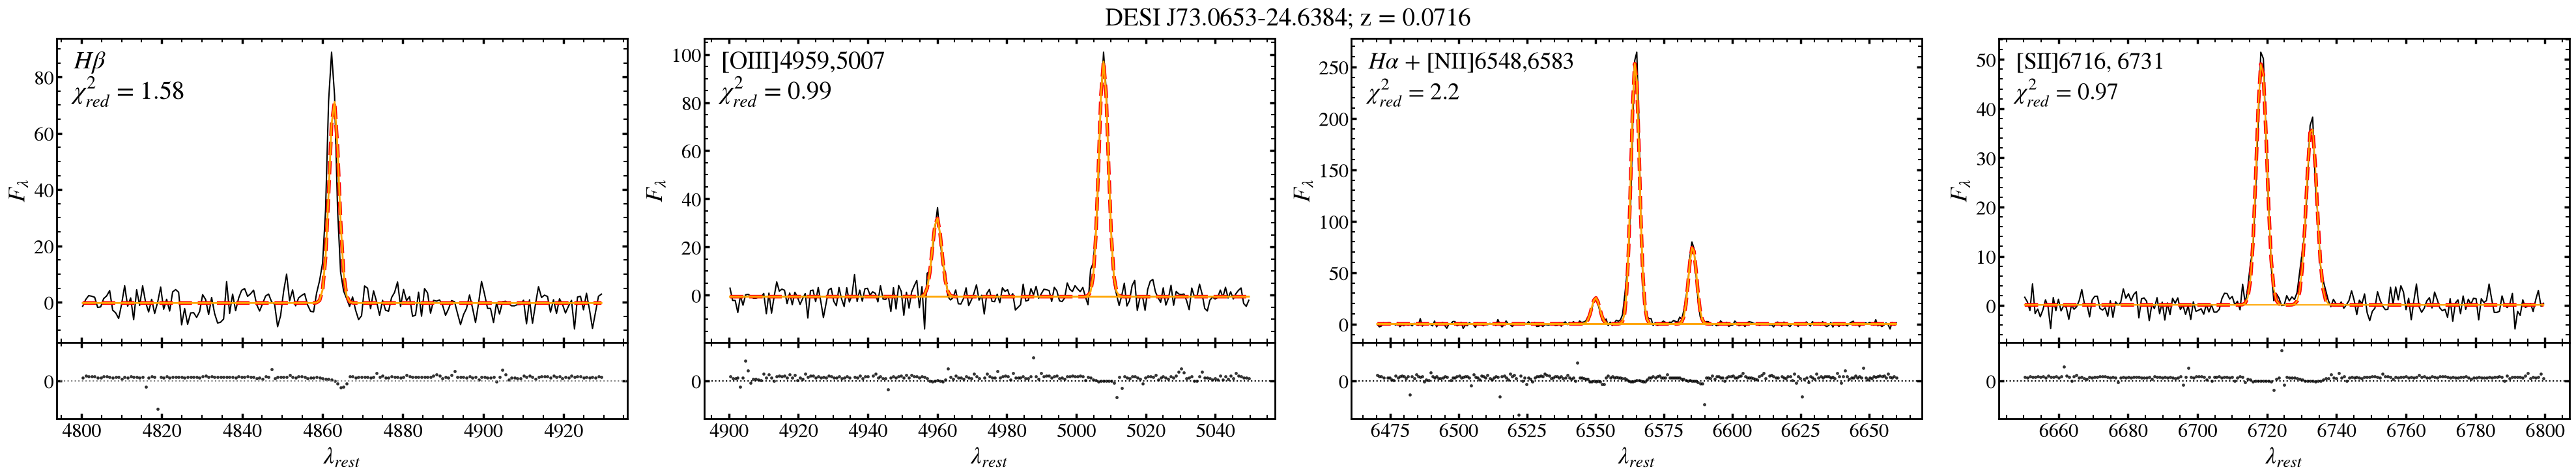

In [8]:
## Narrow-Line Candidate
f_nl = wrapper_example_fit(targetid = 2305843045674779000)
# f_nl.savefig('F09a_NL_example.png')
f_nl

INFO:spectra.py:469:read_spectra: iotime 0.509 sec to read spectra from:  coadd-main-dark-27283.fits at 2026-10-05T11:24:49.748093
INFO:coaddition.py:1395:coadd_cameras: coadding spectra across cameras took: 0.058 [sec]


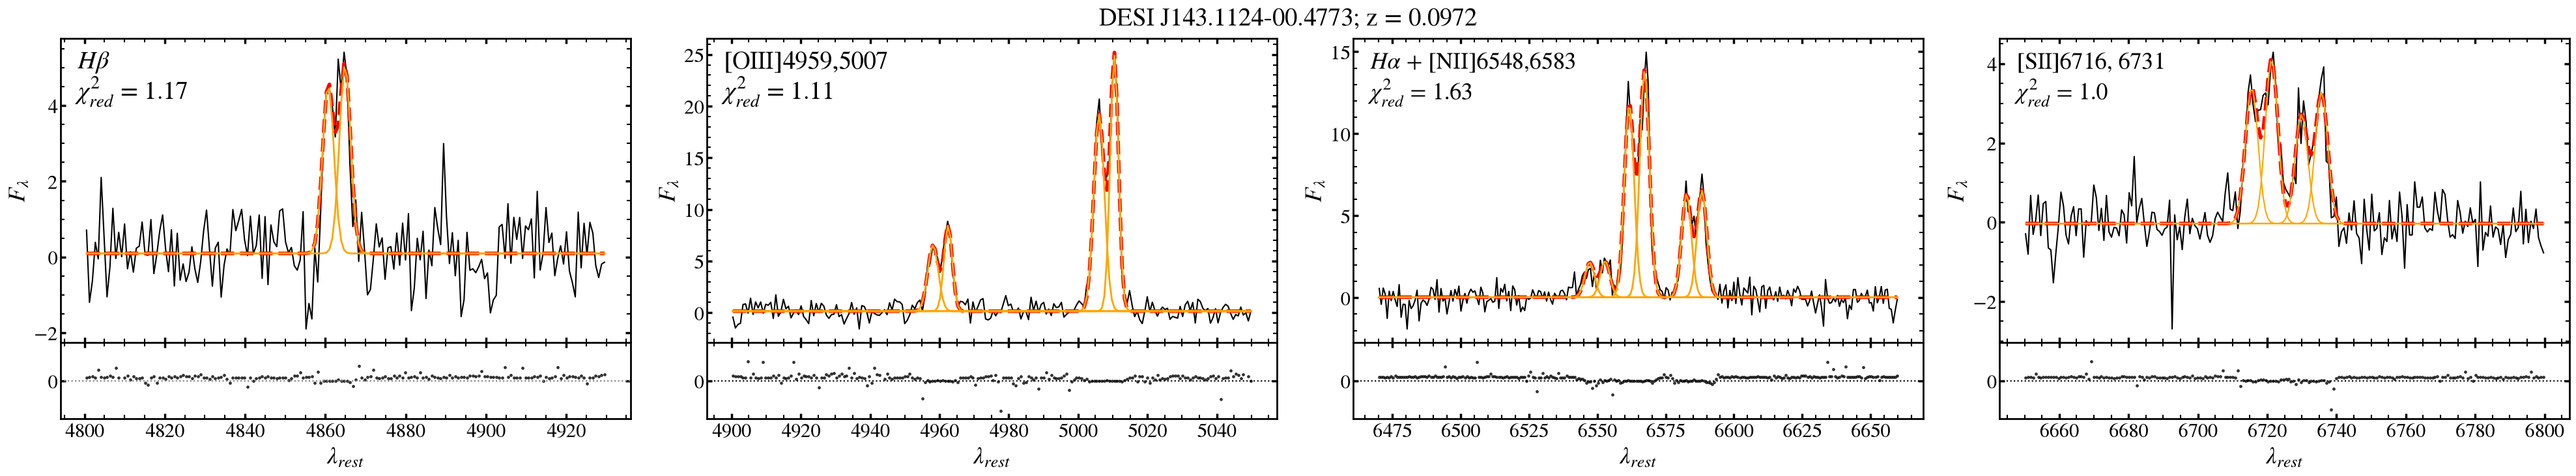

In [9]:
## Double-Peaked Candidate
f_dbl = wrapper_example_fit(targetid = 2842514029543424)
# f_dbl.savefig('F09b_DoublePeak_example.png')
f_dbl

INFO:spectra.py:469:read_spectra: iotime 0.444 sec to read spectra from:  coadd-main-dark-40910.fits at 2026-10-05T11:24:54.636979
INFO:coaddition.py:1395:coadd_cameras: coadding spectra across cameras took: 0.058 [sec]


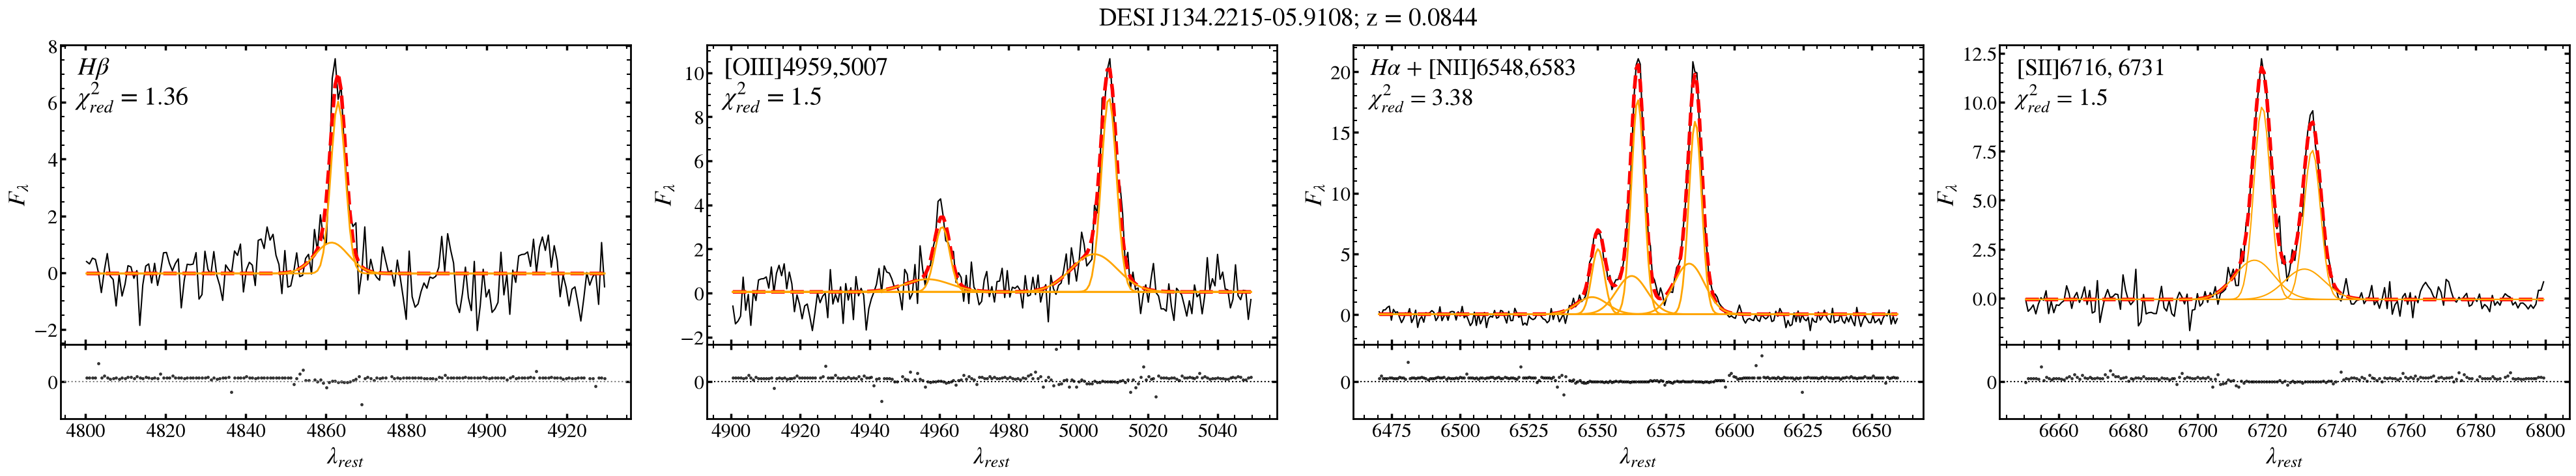

In [10]:
## Outflow Candidate
f_out = wrapper_example_fit(targetid = 2842381179158538)
# f_out.savefig('F09c_Outflows_example.png')
f_out

### Figure 10: Example Fits of galaxy spectra fit via the default mode with broad Balmer components

INFO:spectra.py:469:read_spectra: iotime 0.189 sec to read spectra from:  coadd-main-bright-22537.fits at 2026-10-05T11:24:59.109017
INFO:coaddition.py:1395:coadd_cameras: coadding spectra across cameras took: 0.059 [sec]


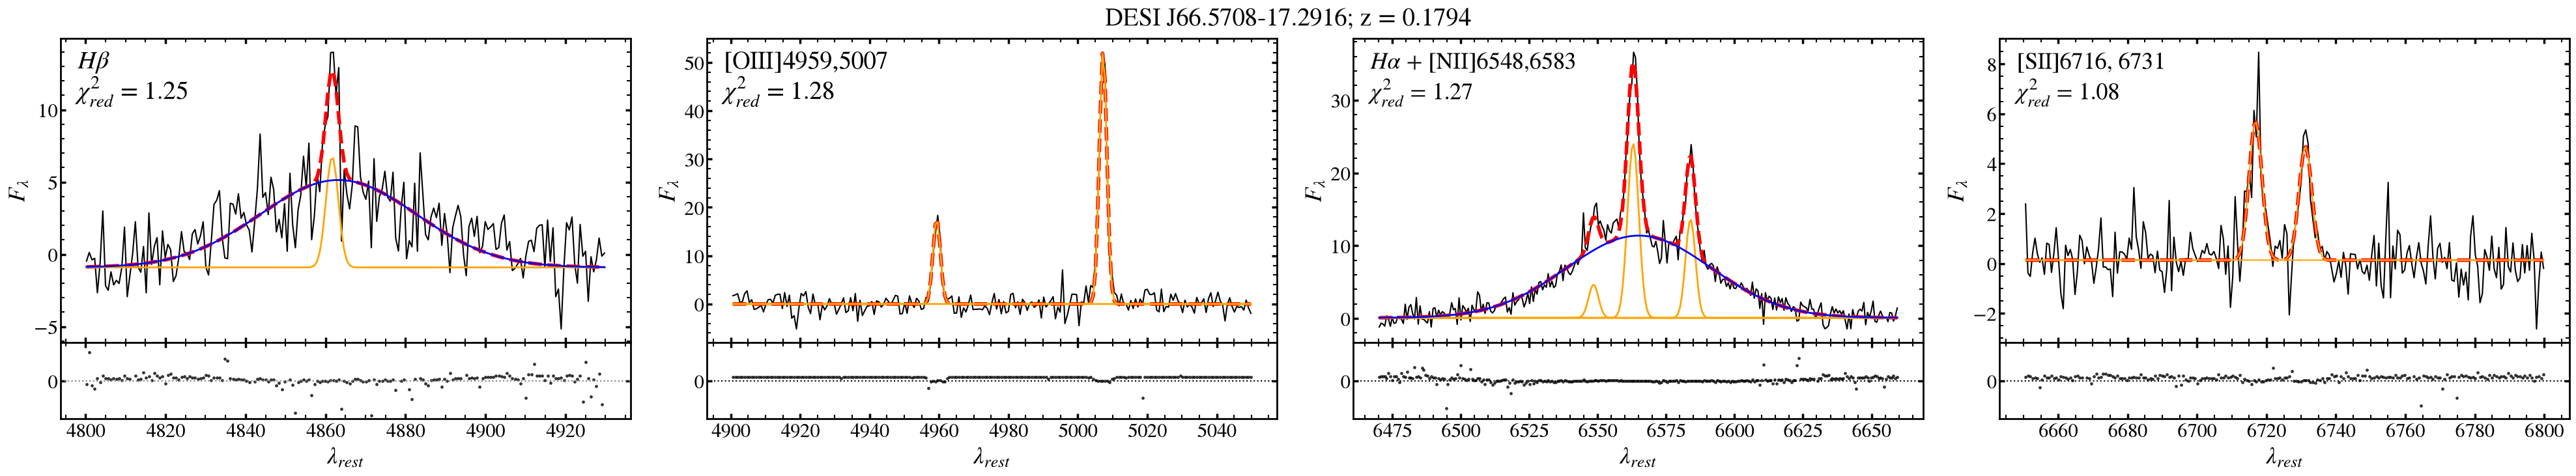

In [11]:
## Narrow + Broad
f_b = wrapper_example_fit(targetid = 39627375062814549)
# f_b.savefig('F10a_NL_wBroad.png')
f_b

INFO:spectra.py:469:read_spectra: iotime 0.178 sec to read spectra from:  coadd-main-dark-4706.fits at 2026-10-05T11:25:02.552252
INFO:coaddition.py:1395:coadd_cameras: coadding spectra across cameras took: 0.059 [sec]


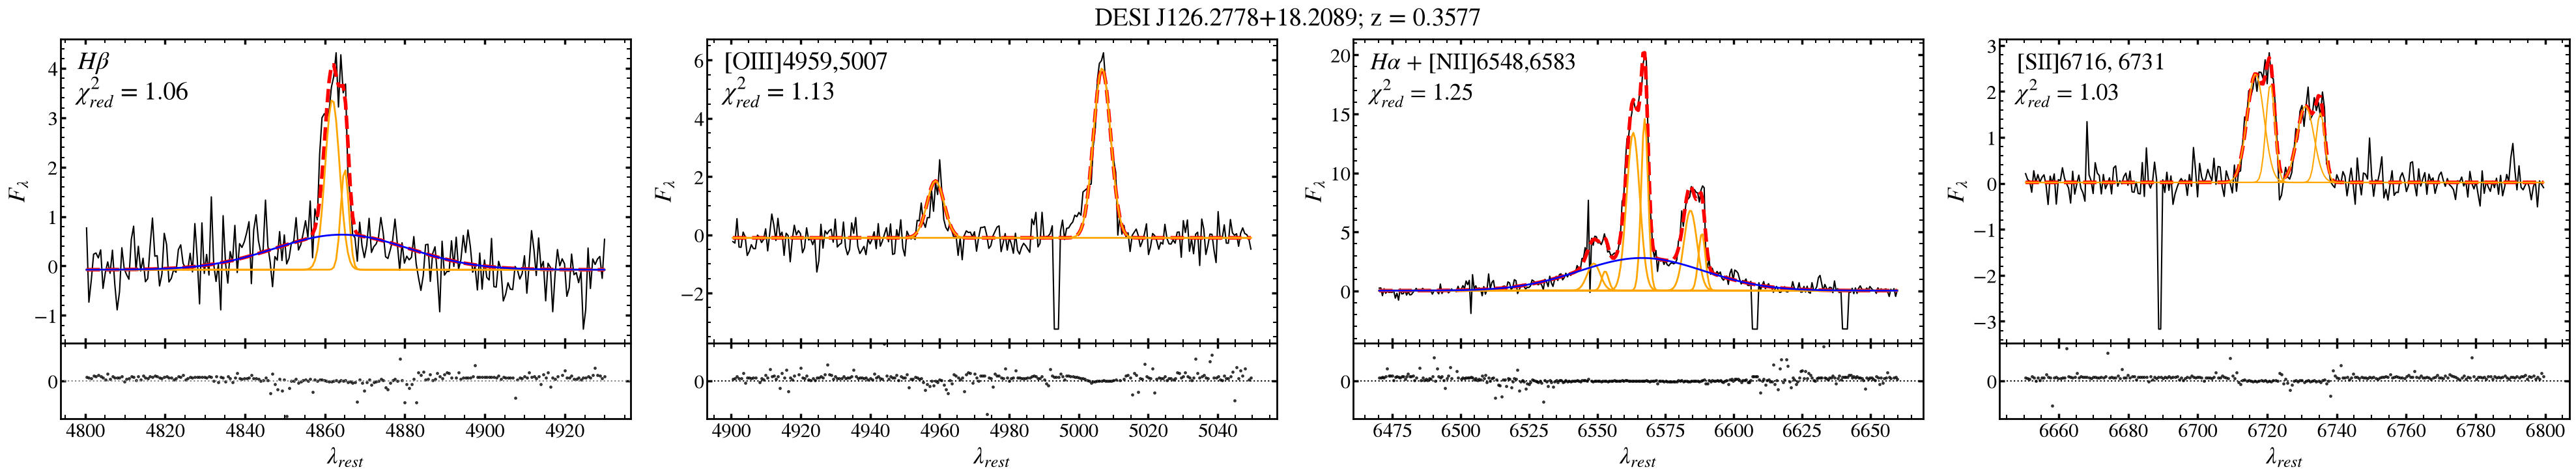

In [12]:
## Double-Peaked + Broad
f_dbl_b = wrapper_example_fit(targetid = 39628220802271652)
# f_dbl_b.savefig('F10b_DoublePeak_wBroad.png')
f_dbl_b

INFO:spectra.py:469:read_spectra: iotime 0.125 sec to read spectra from:  coadd-main-bright-18572.fits at 2026-10-05T11:25:05.919441
INFO:coaddition.py:1395:coadd_cameras: coadding spectra across cameras took: 0.060 [sec]


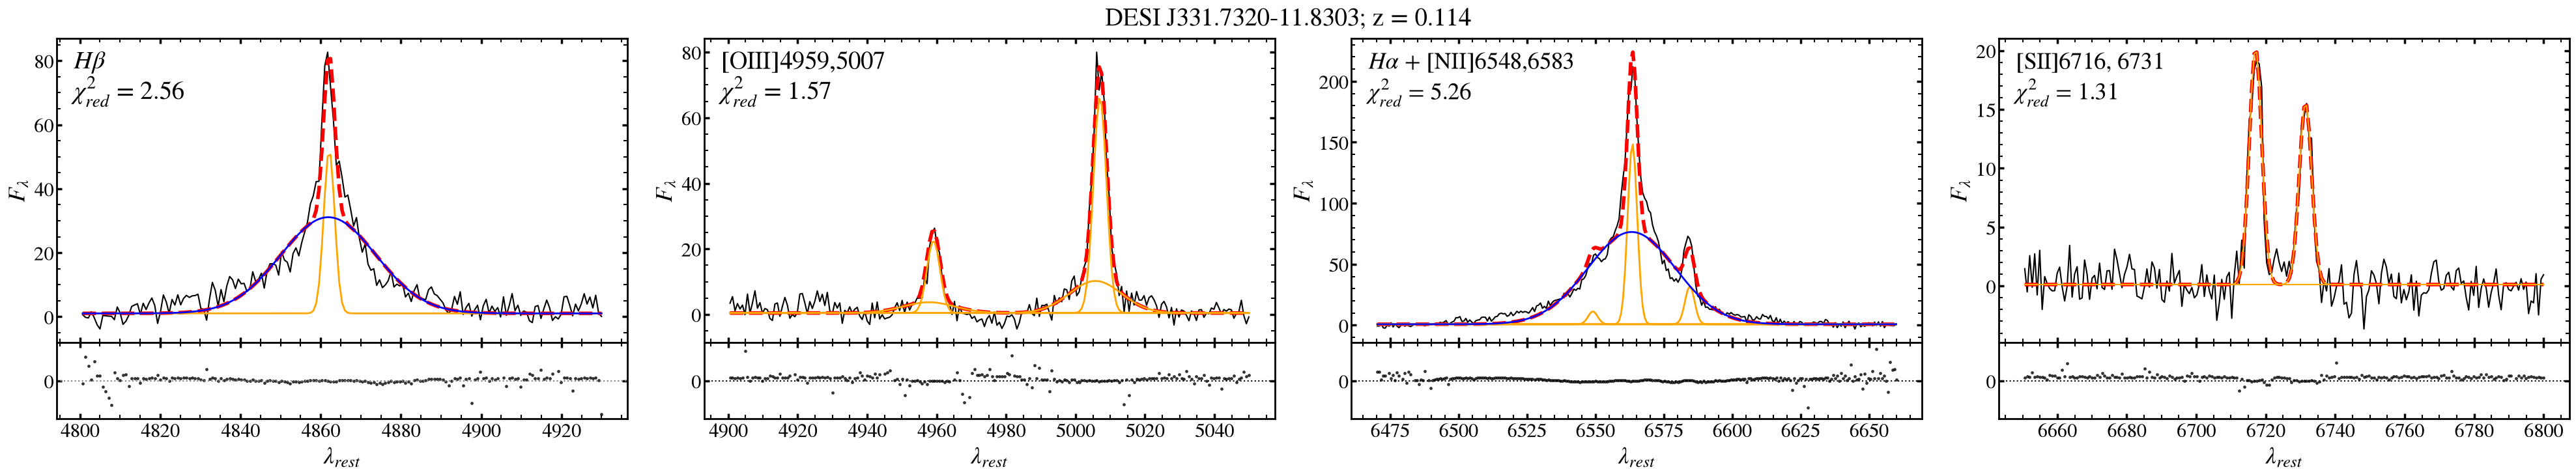

In [13]:
## Outflow + Broad
f_out_b = wrapper_example_fit(targetid = 39627508127105687)
# f_out_b.savefig('F10c_Outflows_wBroad.png')
f_out_b

### Figure 11: Example Fits of Galaxy spectra fit via the EBL Mode

INFO:spectra.py:469:read_spectra: iotime 0.278 sec to read spectra from:  coadd-main-bright-26895.fits at 2026-10-05T11:25:09.187975
INFO:coaddition.py:1395:coadd_cameras: coadding spectra across cameras took: 0.059 [sec]


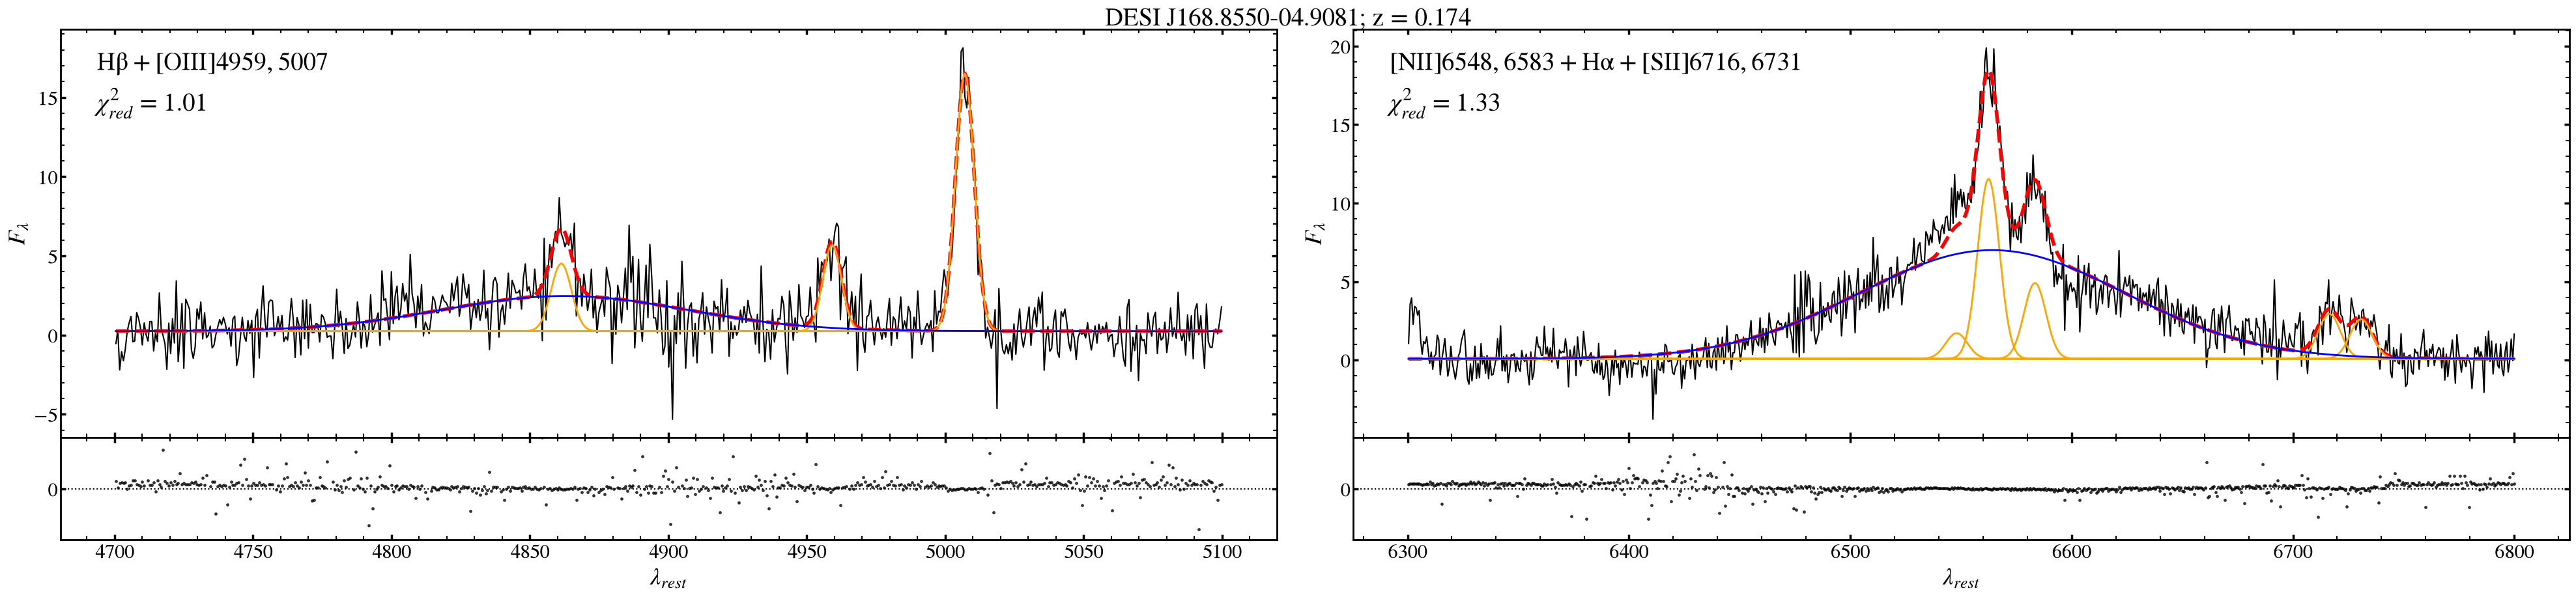

In [14]:
## Without outflows
f_ebl = wrapper_example_fit(targetid = 39627666847959809)
# f_ebl.savefig('F11a_EBL_noOutflows.png')
f_ebl

INFO:spectra.py:469:read_spectra: iotime 0.078 sec to read spectra from:  coadd-main-bright-22659.fits at 2026-10-05T11:25:12.599662
INFO:coaddition.py:1395:coadd_cameras: coadding spectra across cameras took: 0.058 [sec]


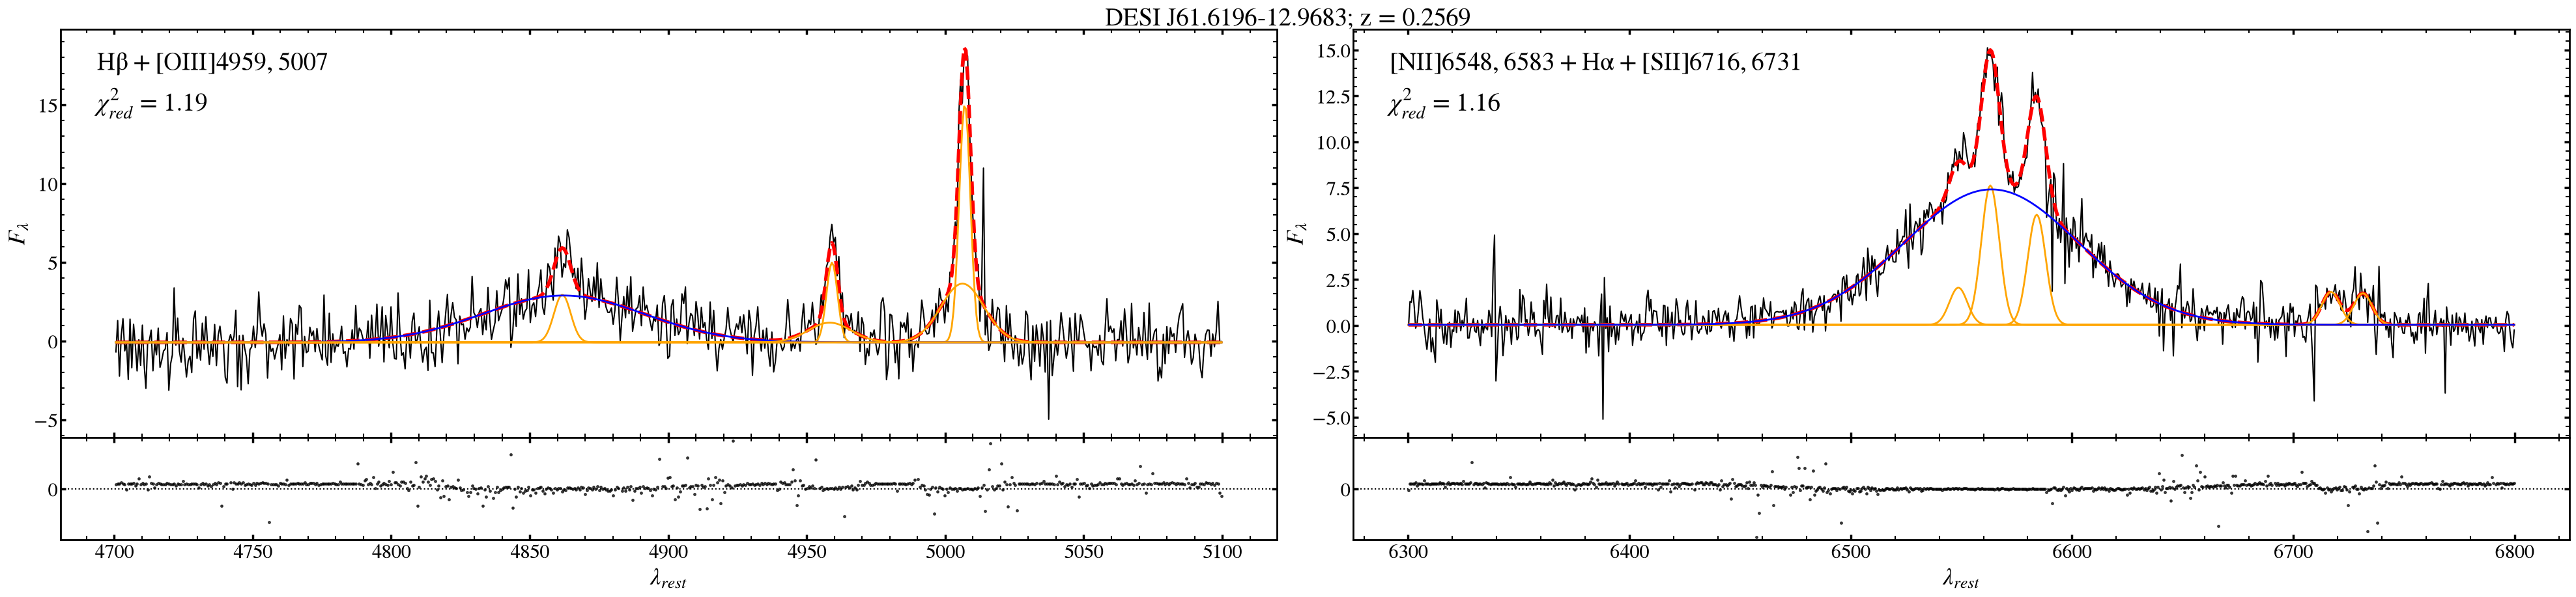

In [15]:
## With Outflows
f_ebl_out = wrapper_example_fit(targetid = 39627474165827392)
# f_ebl_out.savefig('F11b_EBL_wOutflows.png')
f_ebl_out

### Figure 12: Example fits with issues with the second component

INFO:spectra.py:469:read_spectra: iotime 0.127 sec to read spectra from:  coadd-main-dark-22569.fits at 2026-10-05T11:25:15.270935
INFO:coaddition.py:1395:coadd_cameras: coadding spectra across cameras took: 0.058 [sec]


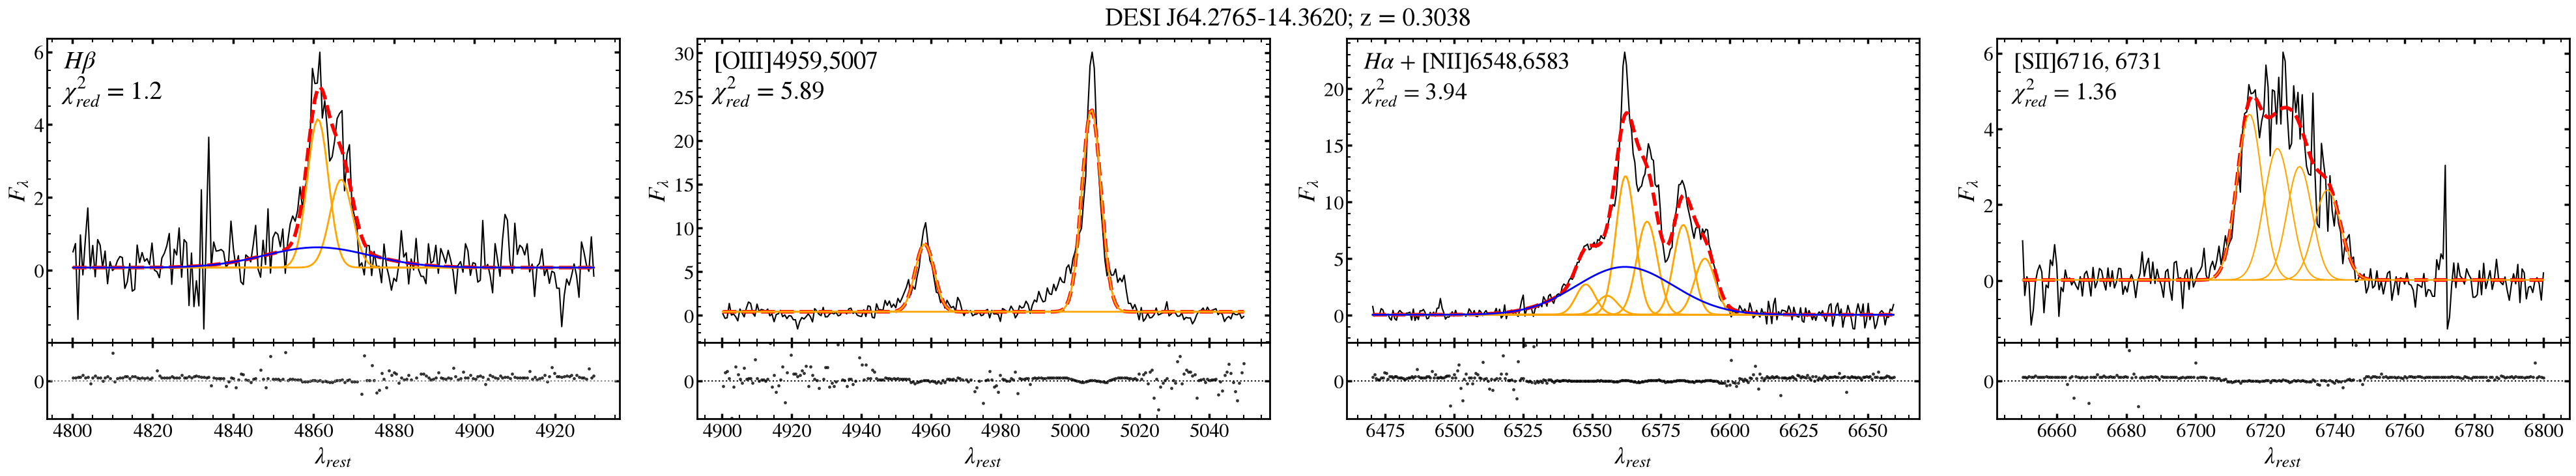

In [16]:
## Missed Outflow
f_missed_out = wrapper_example_fit(targetid = 39627444835061057)
# f_missed_out.savefig('F12a_Missed_Outflow.png')
f_missed_out

INFO:spectra.py:469:read_spectra: iotime 0.340 sec to read spectra from:  coadd-special-other-27333.fits at 2026-10-05T11:25:18.657315
INFO:coaddition.py:1395:coadd_cameras: coadding spectra across cameras took: 0.058 [sec]


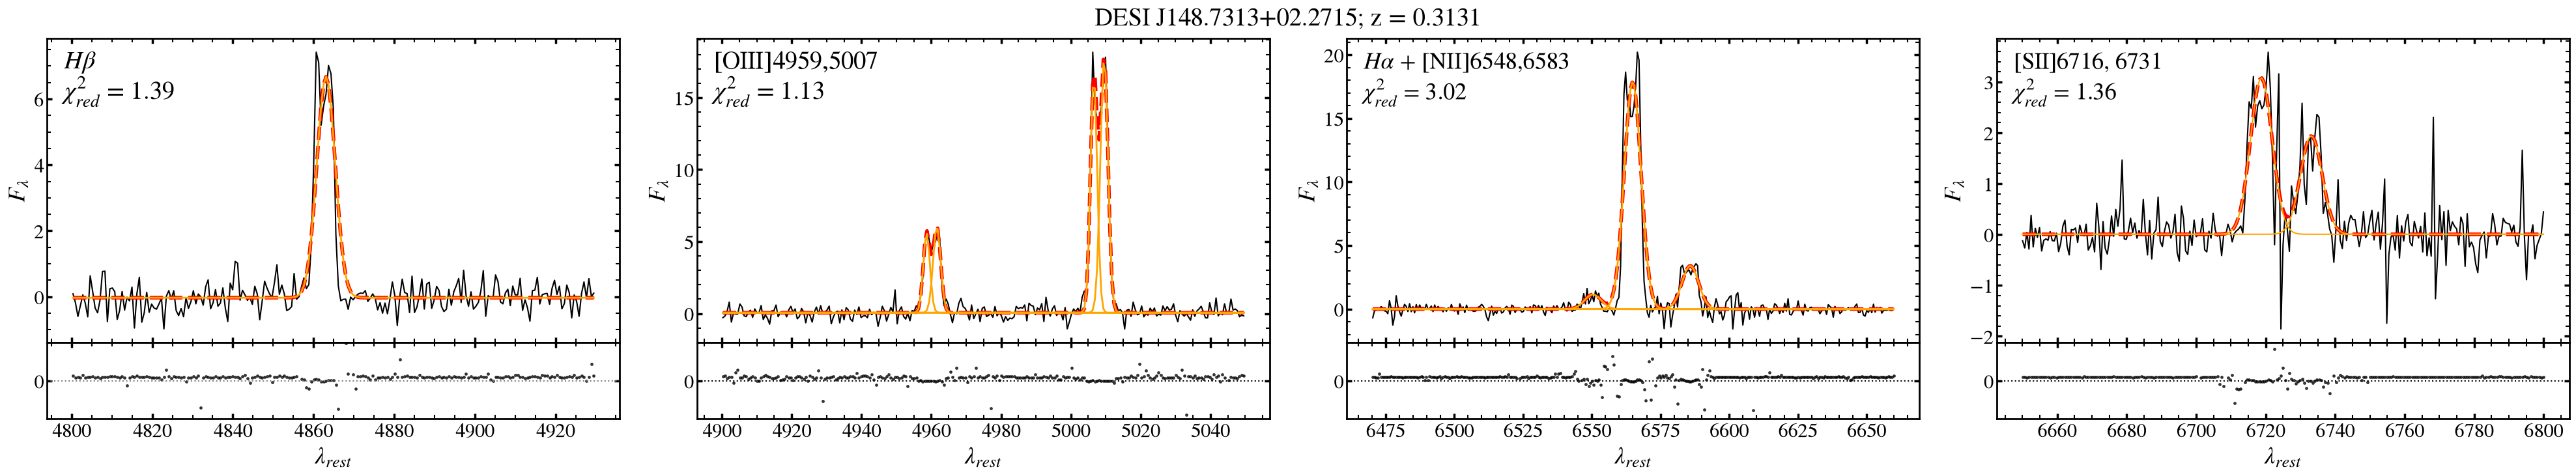

In [17]:
## Missed Second component
f_missed_dbl = wrapper_example_fit(targetid = 39089837394965960)
# f_missed_dbl.savefig('F12b_Missed_doublepeak.png')
f_missed_dbl

INFO:spectra.py:469:read_spectra: iotime 0.473 sec to read spectra from:  coadd-main-dark-9732.fits at 2026-10-05T11:25:22.980548
INFO:coaddition.py:1395:coadd_cameras: coadding spectra across cameras took: 0.059 [sec]


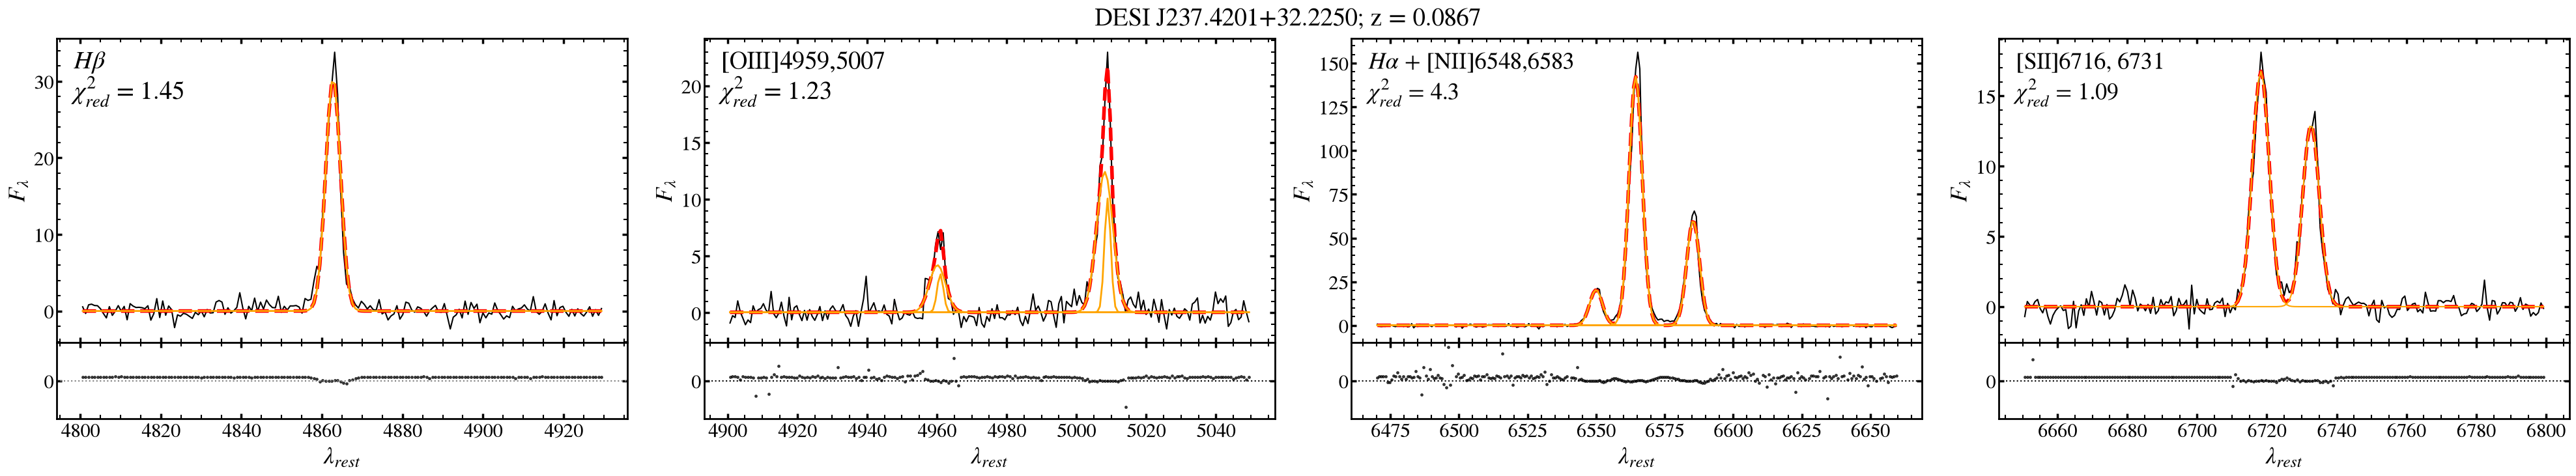

In [18]:
## Forced Second Component
f_forced = wrapper_example_fit(targetid = 2852063243403264)
# f_forced.savefig('F12c_Forced_Extra.png')
f_forced

### Figure 13: Example Fits showing issues with single Gaussian broad component

INFO:spectra.py:469:read_spectra: iotime 0.178 sec to read spectra from:  coadd-main-dark-18793.fits at 2026-10-05T11:25:27.527366
INFO:coaddition.py:1395:coadd_cameras: coadding spectra across cameras took: 0.058 [sec]


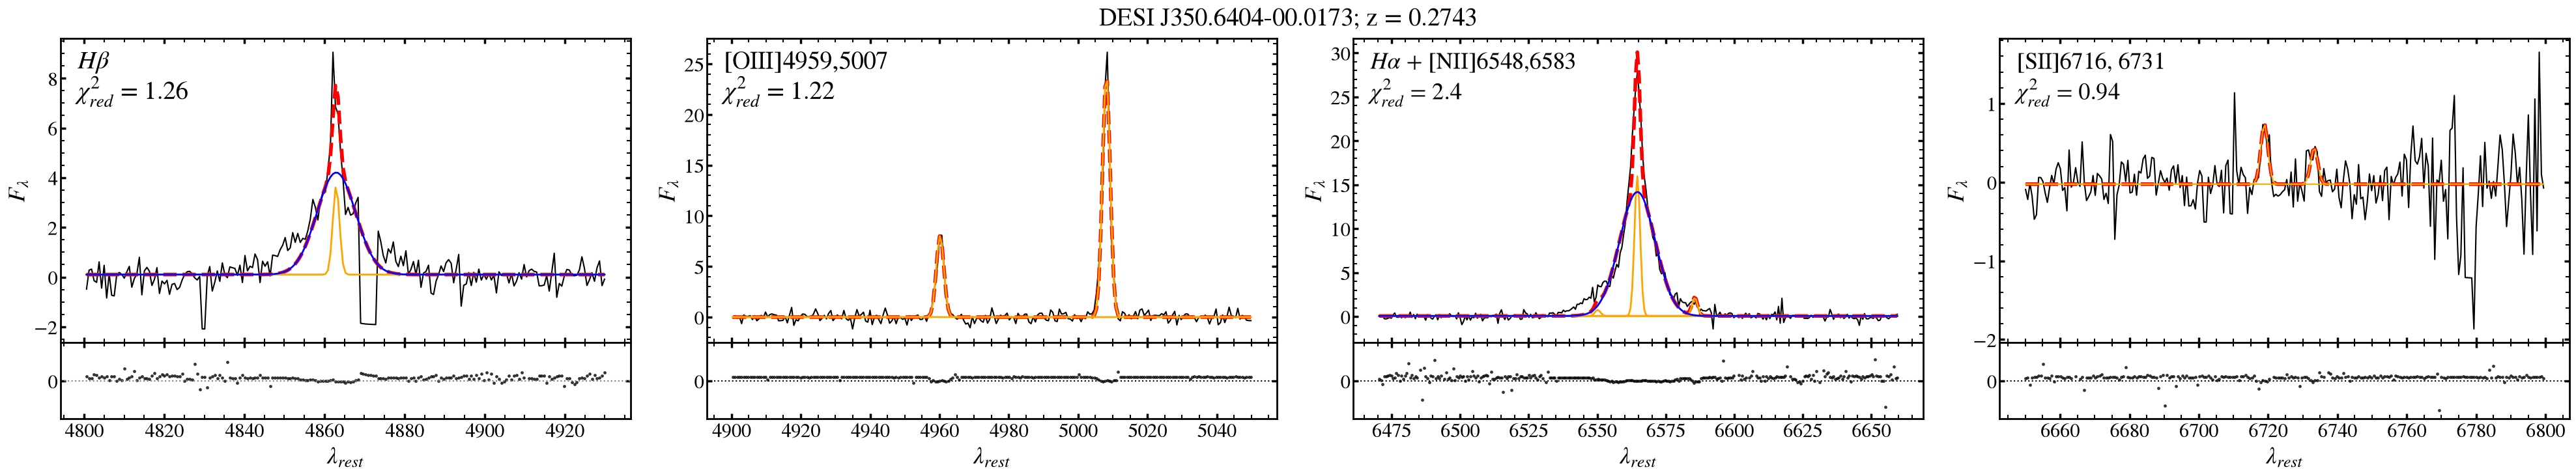

In [19]:
## Default mode
f_def_g = wrapper_example_fit(targetid = 39627790609290083)
# f_def_g.savefig('F13a_Default_Gaussian.png')
f_def_g

INFO:spectra.py:469:read_spectra: iotime 0.194 sec to read spectra from:  coadd-main-dark-4477.fits at 2026-10-05T11:25:30.909241
INFO:coaddition.py:1395:coadd_cameras: coadding spectra across cameras took: 0.059 [sec]


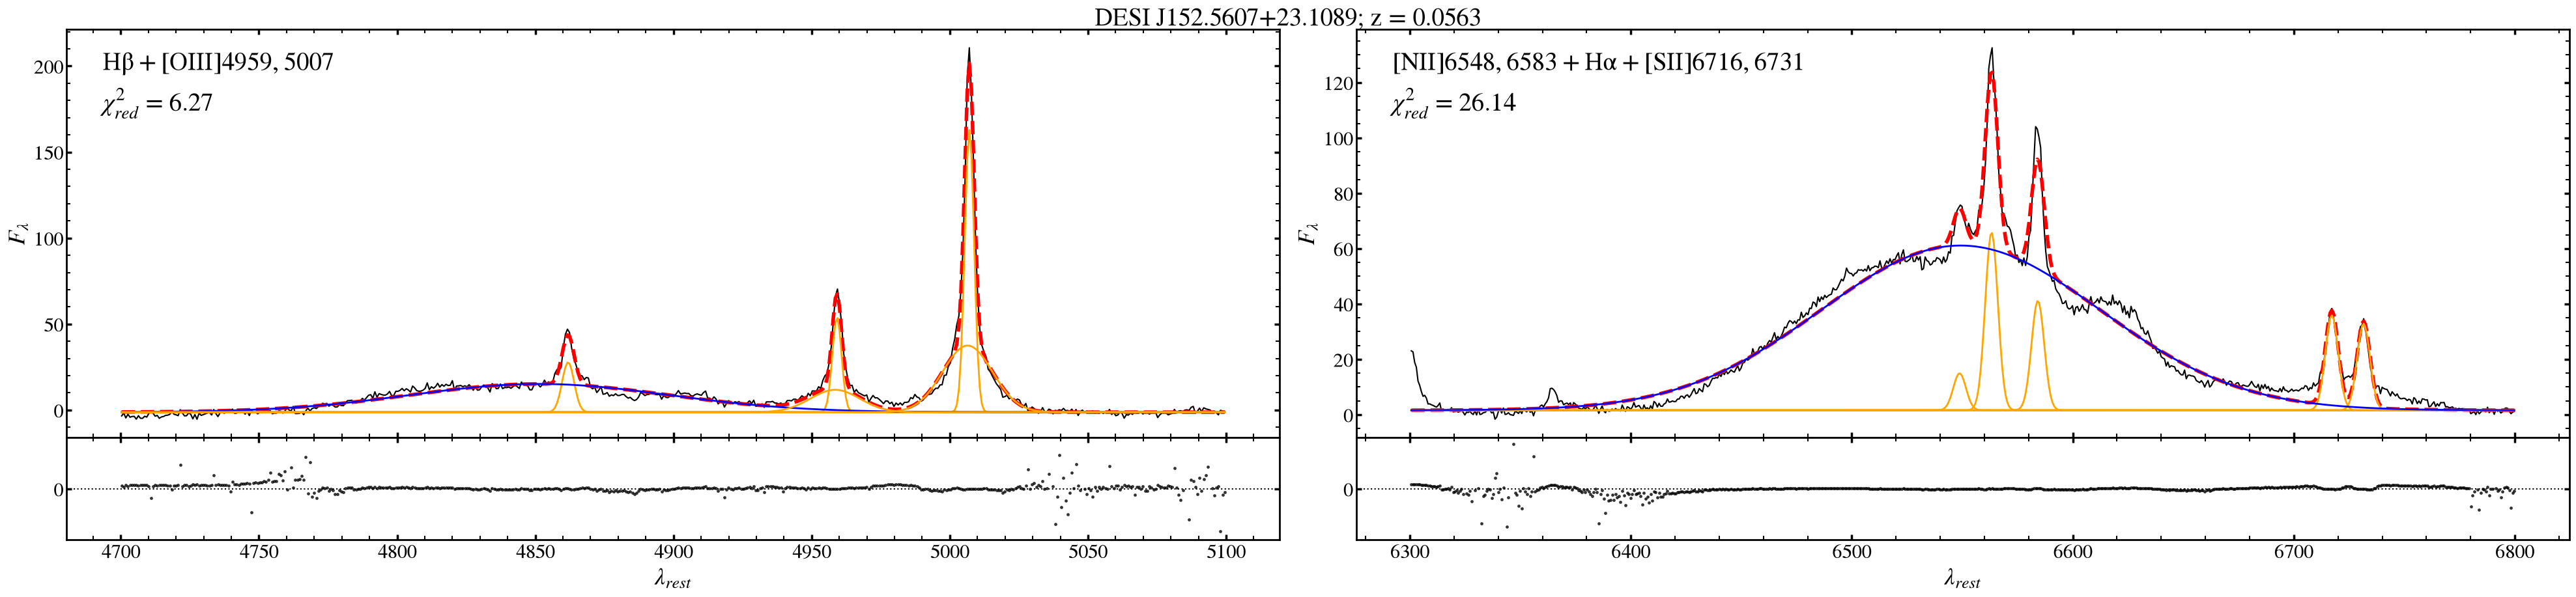

In [20]:
## EBL Mode
f_ebl_g = wrapper_example_fit(targetid = 39628328780434730)
# f_ebl_g.savefig('F13b_EBL_Gaussian.png')
f_ebl_g

### Figure 14: Example fits with unclear origin of broad components

INFO:spectra.py:469:read_spectra: iotime 0.209 sec to read spectra from:  coadd-main-bright-10993.fits at 2026-10-05T11:25:34.077895
INFO:coaddition.py:1395:coadd_cameras: coadding spectra across cameras took: 0.059 [sec]


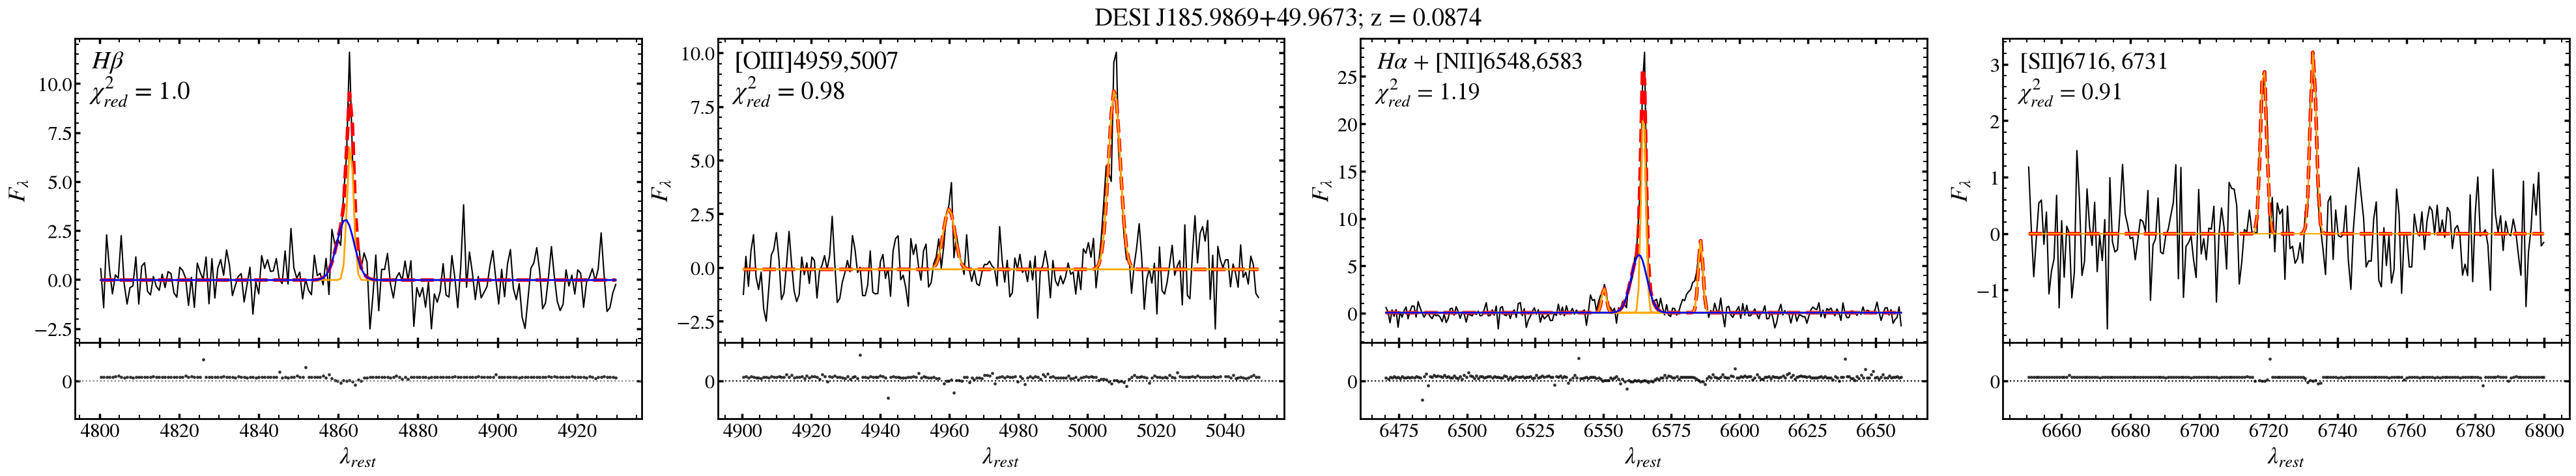

In [21]:
# Missed Outflow
f_missed_b = wrapper_example_fit(targetid = 39633248128599724)
# f_missed_b.savefig('F14a_Missed_Outflow_Broad.png')
f_missed_b

INFO:spectra.py:469:read_spectra: iotime 0.320 sec to read spectra from:  coadd-main-dark-0.fits at 2026-10-05T11:25:37.875755
INFO:coaddition.py:1395:coadd_cameras: coadding spectra across cameras took: 0.058 [sec]


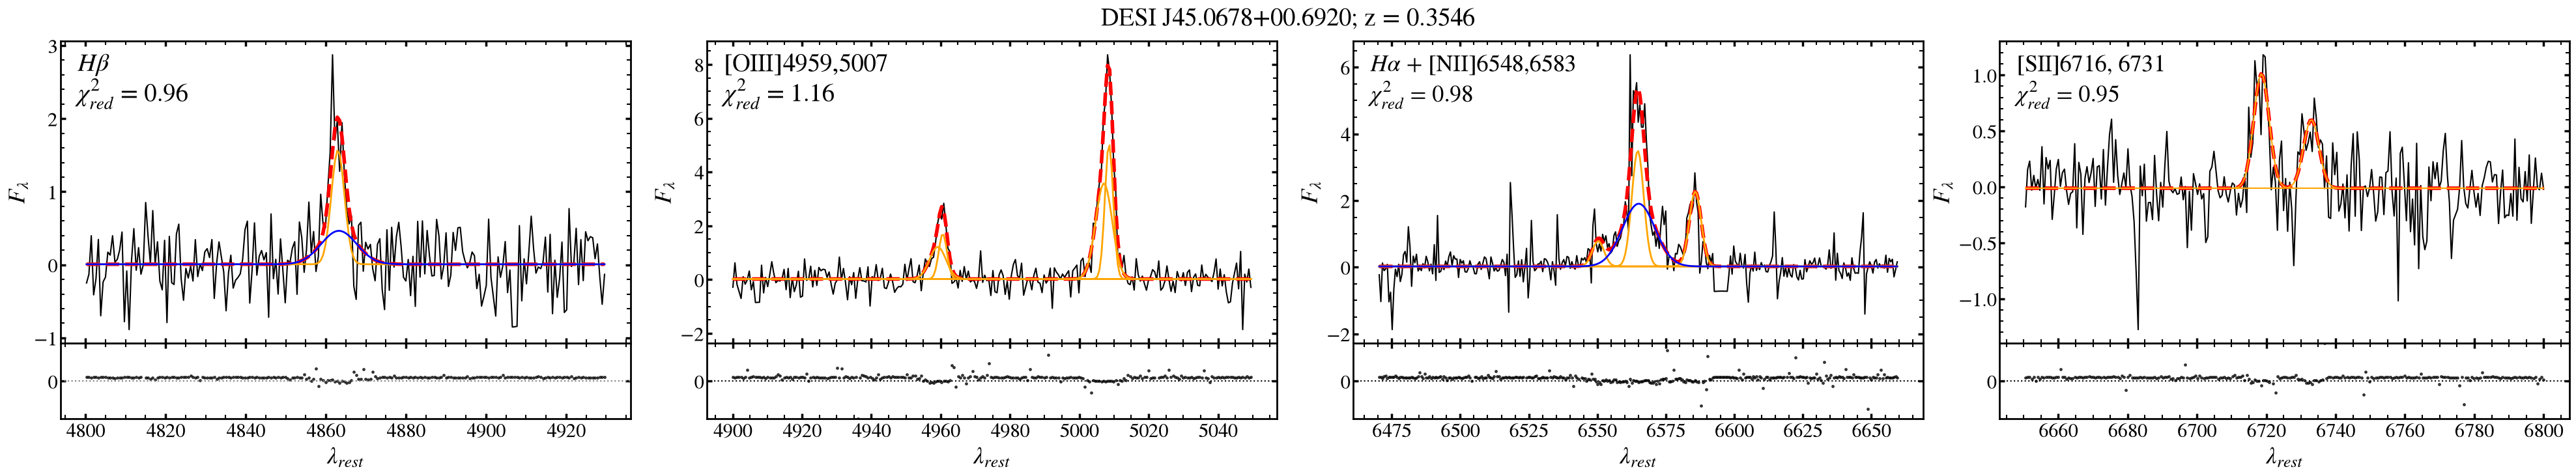

In [22]:
## Tentative BL
f_tent = wrapper_example_fit(targetid = 39627803603241051)
# f_tent.savefig('F14b_Tentative_BL.png')
f_tent

INFO:spectra.py:469:read_spectra: iotime 0.256 sec to read spectra from:  coadd-main-bright-26812.fits at 2026-10-05T11:25:41.858980
INFO:coaddition.py:1395:coadd_cameras: coadding spectra across cameras took: 0.058 [sec]


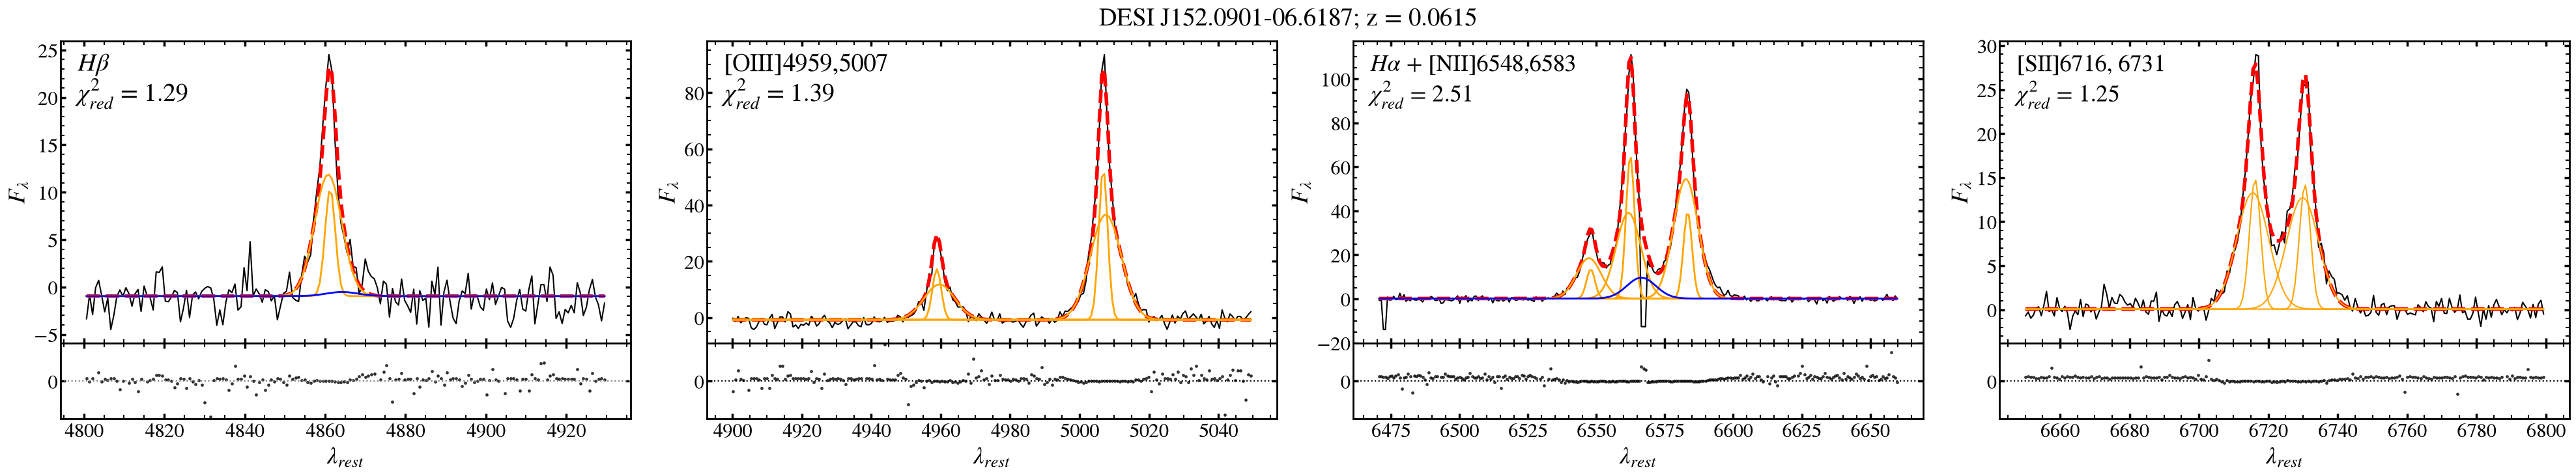

In [23]:
## Complicated Kinematics
f_comp = wrapper_example_fit(targetid = 39627630479152697)
# f_comp.savefig('F14c_complicated_BL.png')
f_comp

### Figure 15: Examples of Complicated Fits

INFO:spectra.py:469:read_spectra: iotime 0.254 sec to read spectra from:  coadd-main-bright-25821.fits at 2026-10-05T11:25:45.444990
INFO:coaddition.py:1395:coadd_cameras: coadding spectra across cameras took: 0.058 [sec]


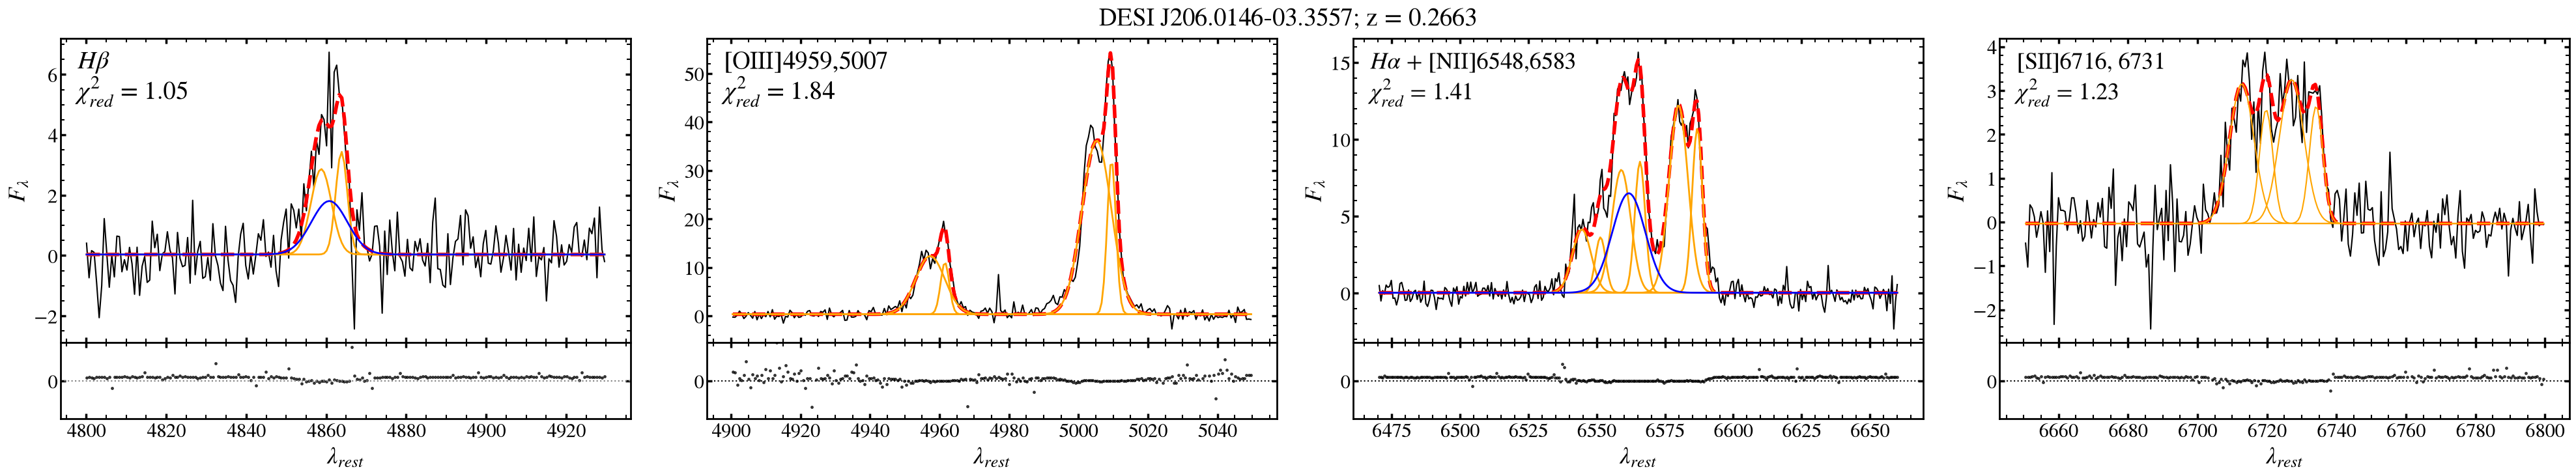

In [24]:
## Good fit, unclear kinematics
f_good = wrapper_example_fit(targetid = 39627709667611890)
# f_good.savefig('F15a_complicated_good_fit.png')
f_good

INFO:spectra.py:469:read_spectra: iotime 0.070 sec to read spectra from:  coadd-sv1-dark-5072.fits at 2026-10-05T11:25:48.907335
INFO:coaddition.py:1395:coadd_cameras: coadding spectra across cameras took: 0.058 [sec]


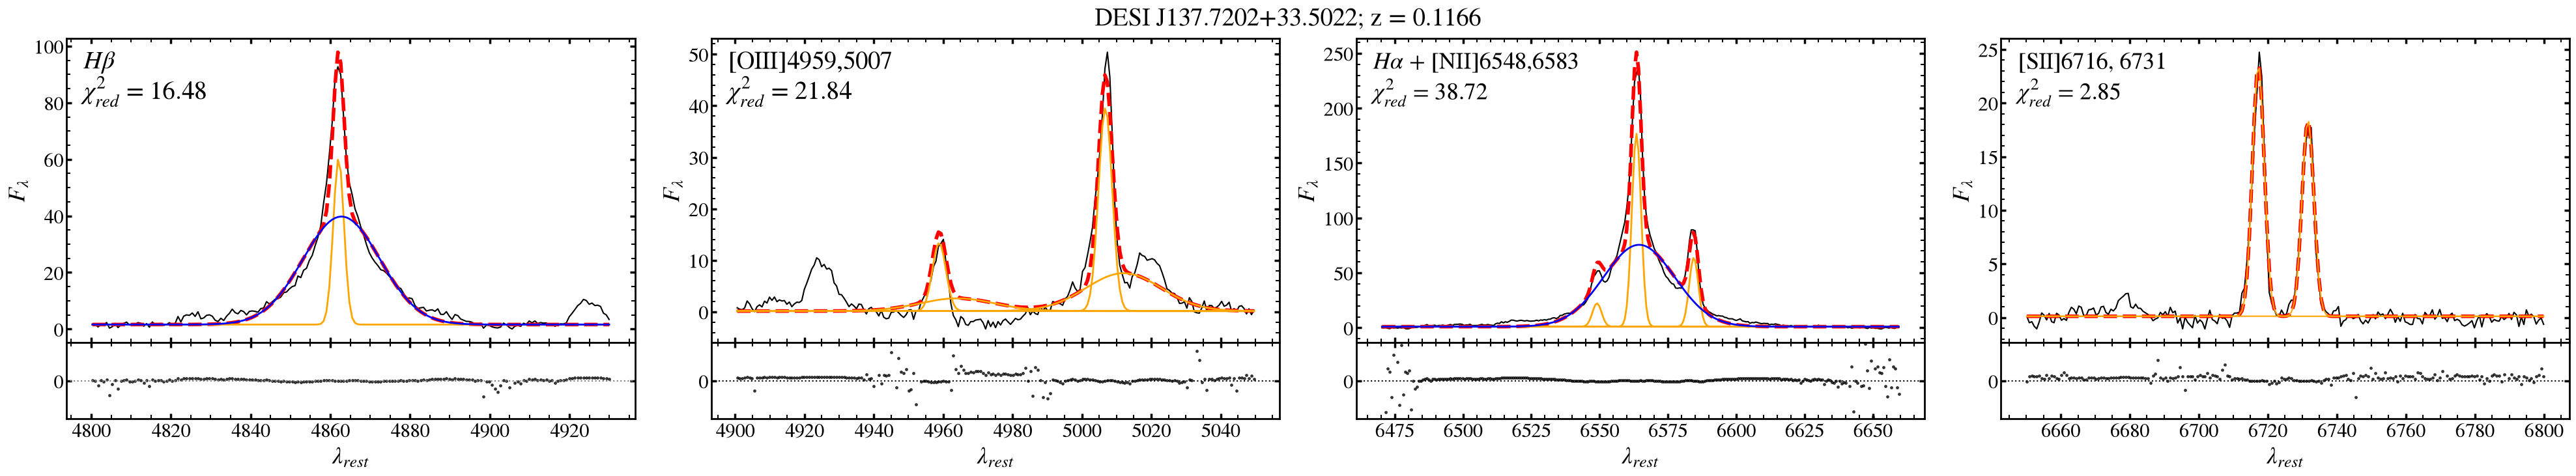

In [25]:
## Bad Continuum Subtraction
f_bad = wrapper_example_fit(targetid = 39632950223964423)
# f_bad.savefig('F15b_BadContinuum.png')
f_bad

---